# Impact of Duplicate Training Samples on Machine Learning Generalization

An experimental study of how adding different percentages of duplicate records to training data affects the performance and generalization of multiple machine learning classifiers.

**Dataset:** UCI Internet Firewall Data  
**Models:** Logistic Regression, Decision Tree, Random Forest and K-Nearest Neighbors (KNN)


## Problem Statement

To investigate how increasing the number of duplicate training samples affects the predictive performance and generalization of different machine learning models.

## Objectives

- Compare four classification algorithms.
- Test duplicate levels of 0%, 10%, 25%, 50%, 75% and 100%.
- Evaluate models using multiple performance metrics.
- Examine training time and the training–testing generalization gap.


## Dataset

The project uses the UCI Internet Firewall Data dataset. It contains firewall traffic records with 11 input attributes and the target column `Action`, which has four classes: `allow`, `deny`, `drop` and `reset-both`. The original dataset contains 65,532 records. Exact duplicate rows are removed before the train-test split.

**Dataset source:** [UCI Internet Firewall Data](https://archive.ics.uci.edu/dataset/542/internet%2Bfirewall%2Bdata)  
**DOI:** `10.24432/C5131M`

## Experimental Method

The cleaned data is split into 80% training and 20% testing data using stratification. Duplicate rows are sampled with replacement from the training set only and added at six levels: 0%, 10%, 25%, 50%, 75% and 100% of the original training-set size. The four models are evaluated on the same untouched test set. The experiment is repeated with two duplicate-sampling seeds: 42 and 123.

The notebook reports accuracy, weighted precision, weighted recall, weighted F1, macro F1, ROC-AUC, generalization gap and training time.


In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn

import os
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

from IPython.display import display

os.makedirs("project_outputs", exist_ok=True)
print("Libraries imported and output folder created.")


Libraries imported and output folder created.


In [2]:
url = "https://raw.githubusercontent.com/balarabetahir/Firewall-Log-Classification-with-Machine-Learning.ipynb/main/log2.csv"

df = pd.read_csv(url)
df.columns = df.columns.str.strip()
df["Action"] = df["Action"].astype(str).str.strip().str.lower()

print("DATASET LOADED")
print("Original shape:", df.shape)
print("\nFirst five records:")
display(df.head())


DATASET LOADED
Original shape: (65532, 12)

First five records:


,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65532 entries, 0 to 65531
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Source Port           65532 non-null  int64 
 1   Destination Port      65532 non-null  int64 
 2   NAT Source Port       65532 non-null  int64 
 3   NAT Destination Port  65532 non-null  int64 
 4   Action                65532 non-null  object
 5   Bytes                 65532 non-null  int64 
 6   Bytes Sent            65532 non-null  int64 
 7   Bytes Received        65532 non-null  int64 
 8   Packets               65532 non-null  int64 
 9   Elapsed Time (sec)    65532 non-null  int64 
 10  pkts_sent             65532 non-null  int64 
 11  pkts_received         65532 non-null  int64 
dtypes: int64(11), object(1)
memory usage: 6.0+ MB

Missing values:
Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port   

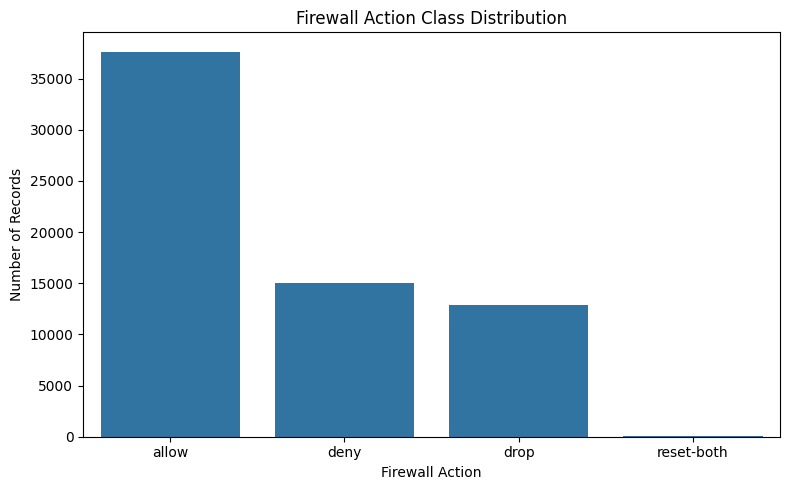

In [3]:
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

original_duplicates = df.duplicated().sum()
print("\nExact duplicate records:", original_duplicates)

print("\nOriginal class distribution:")
print(df["Action"].value_counts())

# Class distribution visualization
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Action", order=df["Action"].value_counts().index)
plt.title("Firewall Action Class Distribution")
plt.xlabel("Firewall Action")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()



Cleaned dataset shape: (57170, 12)
Features: 11
Classes: ['allow', 'deny', 'drop', 'reset-both']
Remaining exact duplicates: 0


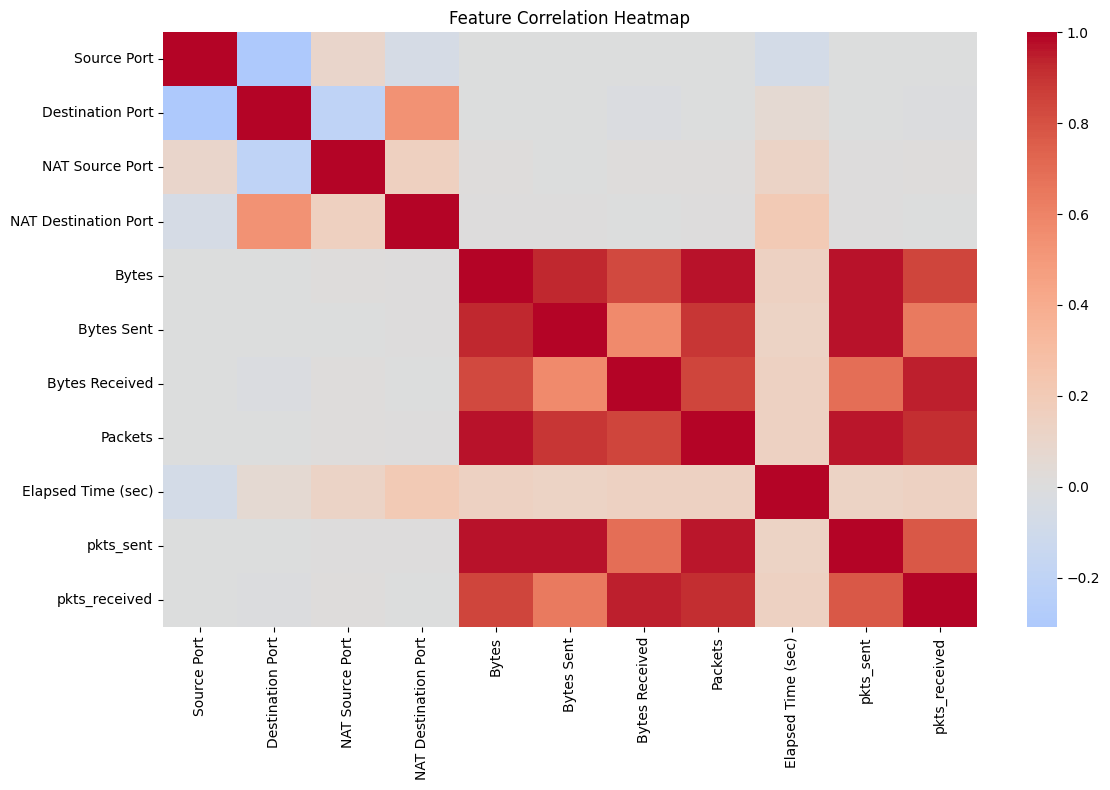

In [4]:
# Remove pre-existing exact duplicate records before splitting
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop("Action", axis=1).apply(pd.to_numeric, errors="coerce")
y_text = df["Action"]

# Handle any missing feature values safely
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)
class_names = encoder.classes_

print("\nCleaned dataset shape:", df.shape)
print("Features:", X.shape[1])
print("Classes:", list(class_names))
print("Remaining exact duplicates:", df.duplicated().sum())

# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 45736
Testing samples: 11434


In [6]:
def create_models():

    return {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000))
        ]),

        "Decision Tree": DecisionTreeClassifier(
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(
                n_neighbors=5,
                n_jobs=-1
            ))
        ])
    }



RANDOM SEED: 42

Duplicates: 0% | Training records: 45736


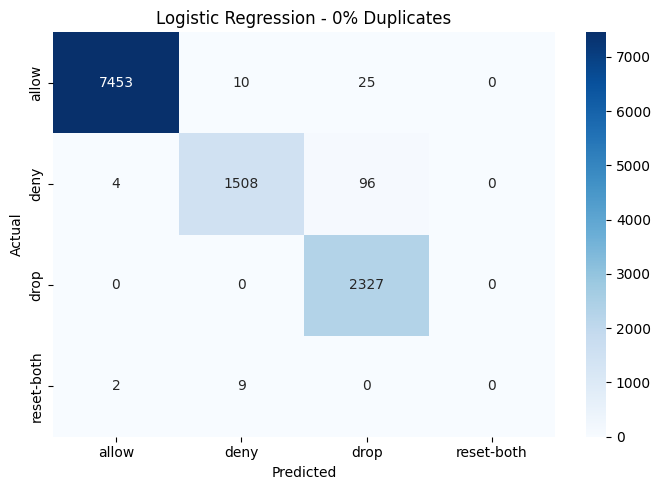

Logistic Regression: Accuracy=0.9872, F1=0.9867, Time=1.31s


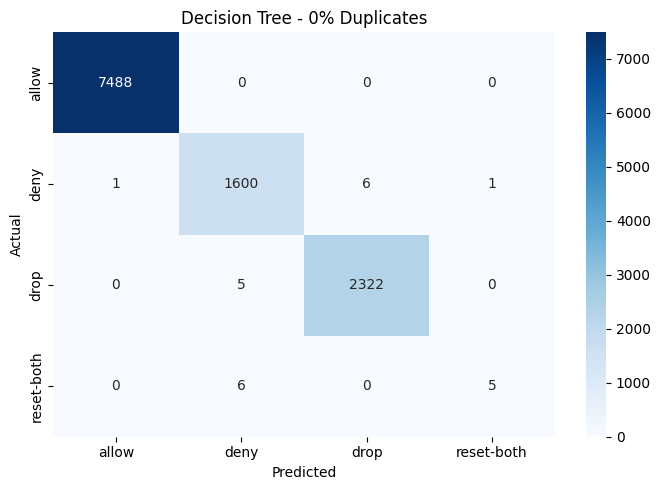

Decision Tree: Accuracy=0.9983, F1=0.9982, Time=0.11s


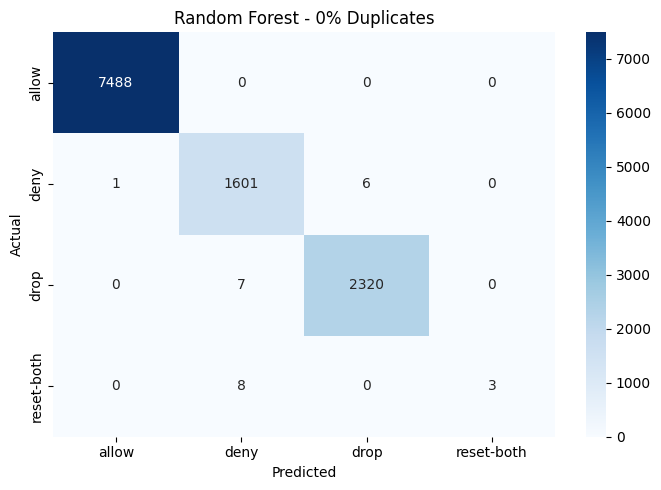

Random Forest: Accuracy=0.9981, F1=0.9979, Time=2.70s


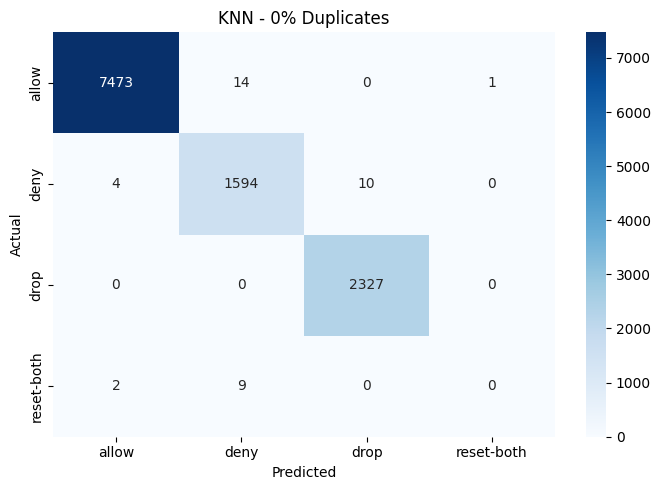

KNN: Accuracy=0.9965, F1=0.9961, Time=0.11s

Duplicates: 10% | Training records: 50309
Logistic Regression: Accuracy=0.9876, F1=0.9871, Time=1.53s
Decision Tree: Accuracy=0.9983, F1=0.9982, Time=0.12s
Random Forest: Accuracy=0.9980, F1=0.9978, Time=3.03s
KNN: Accuracy=0.9963, F1=0.9959, Time=0.11s

Duplicates: 25% | Training records: 57170
Logistic Regression: Accuracy=0.9879, F1=0.9874, Time=1.71s
Decision Tree: Accuracy=0.9984, F1=0.9984, Time=0.14s
Random Forest: Accuracy=0.9980, F1=0.9977, Time=3.38s
KNN: Accuracy=0.9969, F1=0.9964, Time=0.13s

Duplicates: 50% | Training records: 68604
Logistic Regression: Accuracy=0.9883, F1=0.9878, Time=1.97s
Decision Tree: Accuracy=0.9983, F1=0.9983, Time=0.15s
Random Forest: Accuracy=0.9981, F1=0.9979, Time=4.58s
KNN: Accuracy=0.9969, F1=0.9965, Time=0.27s

Duplicates: 75% | Training records: 80038
Logistic Regression: Accuracy=0.9887, F1=0.9882, Time=2.32s
Decision Tree: Accuracy=0.9983, F1=0.9982, Time=0.16s
Random Forest: Accuracy=0.9979, F1

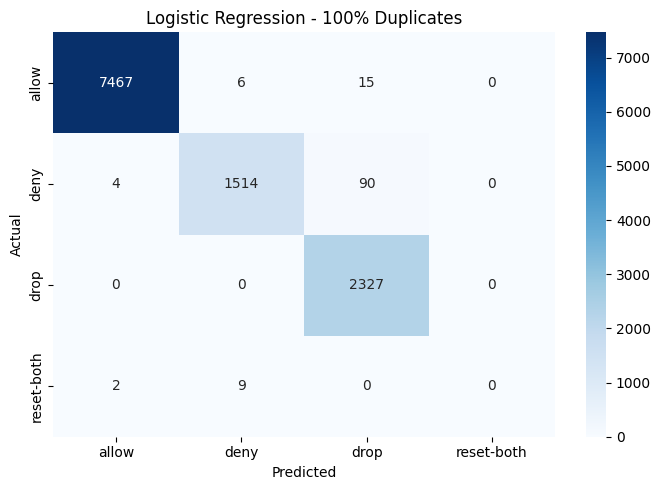

Logistic Regression: Accuracy=0.9890, F1=0.9885, Time=2.12s


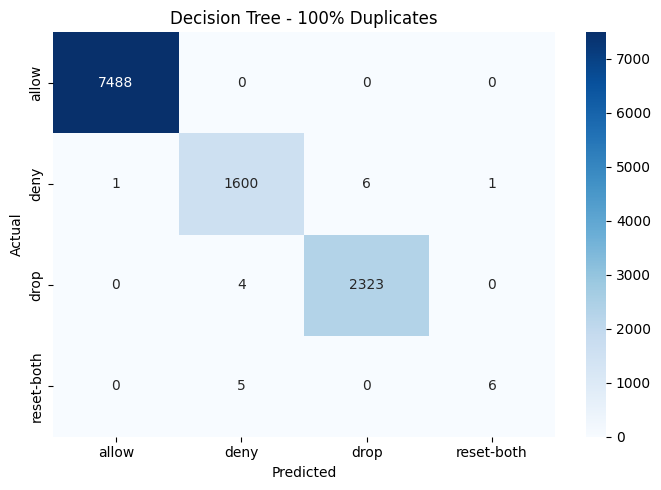

Decision Tree: Accuracy=0.9985, F1=0.9985, Time=0.19s


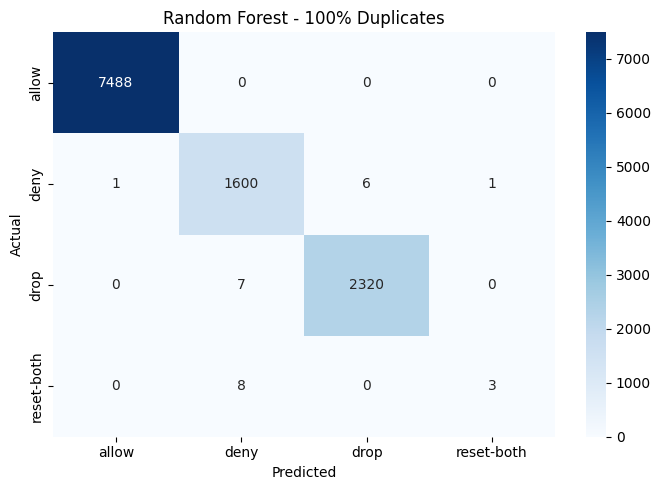

Random Forest: Accuracy=0.9980, F1=0.9978, Time=5.50s


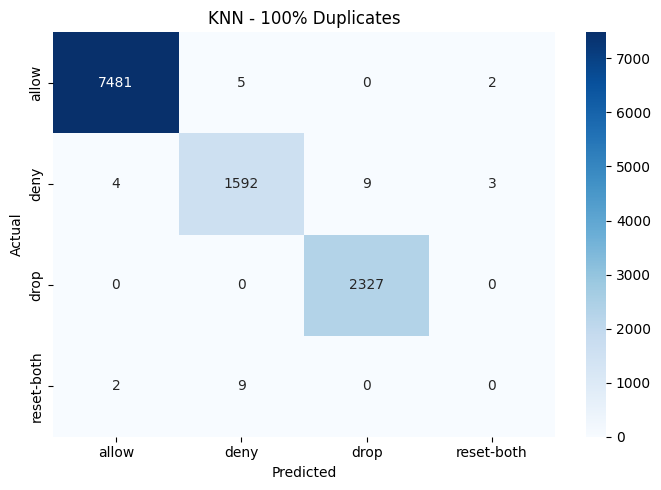

KNN: Accuracy=0.9970, F1=0.9968, Time=0.25s

RANDOM SEED: 123

Duplicates: 0% | Training records: 45736
Logistic Regression: Accuracy=0.9872, F1=0.9867, Time=1.33s
Decision Tree: Accuracy=0.9983, F1=0.9982, Time=0.11s
Random Forest: Accuracy=0.9981, F1=0.9979, Time=4.29s
KNN: Accuracy=0.9965, F1=0.9961, Time=0.10s

Duplicates: 10% | Training records: 50309
Logistic Regression: Accuracy=0.9878, F1=0.9873, Time=1.54s
Decision Tree: Accuracy=0.9984, F1=0.9984, Time=0.13s
Random Forest: Accuracy=0.9977, F1=0.9975, Time=3.37s
KNN: Accuracy=0.9966, F1=0.9962, Time=0.17s

Duplicates: 25% | Training records: 57170
Logistic Regression: Accuracy=0.9880, F1=0.9875, Time=1.55s
Decision Tree: Accuracy=0.9985, F1=0.9984, Time=0.14s
Random Forest: Accuracy=0.9978, F1=0.9976, Time=3.27s
KNN: Accuracy=0.9967, F1=0.9962, Time=0.20s

Duplicates: 50% | Training records: 68604
Logistic Regression: Accuracy=0.9885, F1=0.9880, Time=2.27s
Decision Tree: Accuracy=0.9984, F1=0.9984, Time=0.16s
Random Forest: Ac

In [7]:
duplicate_levels = [0, 10, 25, 50, 75, 100]
seeds = [42, 123]

results = []
reports = []
confusion_data = []
feature_importance = None

for seed in seeds:

    print("\nRANDOM SEED:", seed)

    for level in duplicate_levels:

        n_duplicates = int(len(X_train) * level / 100)

        rng = np.random.RandomState(seed)

        if n_duplicates > 0:

            indices = rng.choice(
                len(X_train),
                size=n_duplicates,
                replace=True
            )

            X_dup = X_train.iloc[indices]
            y_dup = y_train[indices]

            X_exp = pd.concat(
                [X_train, X_dup],
                ignore_index=True
            )

            y_exp = np.concatenate([y_train, y_dup])

        else:

            X_exp = X_train.reset_index(drop=True).copy()
            y_exp = y_train.copy()

        print(
            f"\nDuplicates: {level}% | "
            f"Training records: {len(X_exp)}"
        )

        for model_name, model in create_models().items():

            start = time.time()
            model.fit(X_exp, y_exp)
            training_time = time.time() - start

            train_pred = model.predict(X_exp)
            test_pred = model.predict(X_test)
            probabilities = model.predict_proba(X_test)

            train_acc = accuracy_score(y_exp, train_pred)
            test_acc = accuracy_score(y_test, test_pred)

            precision = precision_score(
                y_test, test_pred,
                average="weighted",
                zero_division=0
            )

            recall = recall_score(
                y_test, test_pred,
                average="weighted",
                zero_division=0
            )

            f1_weighted = f1_score(
                y_test, test_pred,
                average="weighted",
                zero_division=0
            )

            f1_macro = f1_score(
                y_test, test_pred,
                average="macro",
                zero_division=0
            )

            roc = roc_auc_score(
                y_test,
                probabilities,
                multi_class="ovr",
                average="weighted",
                labels=np.arange(len(class_names))
            )

            gap = train_acc - test_acc

            results.append({
                "Seed": seed,
                "Duplicate Level": level,
                "Training Samples": len(X_exp),
                "Model": model_name,
                "Train Accuracy": train_acc,
                "Test Accuracy": test_acc,
                "Precision": precision,
                "Recall": recall,
                "Weighted F1": f1_weighted,
                "Macro F1": f1_macro,
                "ROC-AUC": roc,
                "Generalization Gap": gap,
                "Training Time": training_time
            })

            # Save detailed class-wise report for baseline and 100%
            if seed == 42 and level in [0, 100]:

                report = classification_report(
                    y_test,
                    test_pred,
                    labels=np.arange(len(class_names)),
                    target_names=class_names,
                    output_dict=True,
                    zero_division=0
                )

                for class_name, values in report.items():
                    if isinstance(values, dict):
                        reports.append({
                            "Duplicate Level": level,
                            "Model": model_name,
                            "Class": class_name,
                            **values
                        })

                cm = confusion_matrix(
                    y_test,
                    test_pred,
                    labels=np.arange(len(class_names))
                )

                confusion_data.append({
                    "Duplicate Level": level,
                    "Model": model_name,
                    "Matrix": cm
                })

                plt.figure(figsize=(7,5))
                sns.heatmap(
                    cm,
                    annot=True,
                    fmt="d",
                    cmap="Blues",
                    xticklabels=class_names,
                    yticklabels=class_names
                )
                plt.title(f"{model_name} - {level}% Duplicates")
                plt.xlabel("Predicted")
                plt.ylabel("Actual")
                plt.tight_layout()

                plt.savefig(
                    f"project_outputs/confusion_{model_name.replace(' ','_')}_{level}.png",
                    dpi=250
                )
                plt.show()
                plt.close()

            if (
                seed == 42
                and level == 0
                and model_name == "Random Forest"
            ):

                feature_importance = pd.DataFrame({
                    "Feature": X.columns,
                    "Importance": model.feature_importances_
                }).sort_values("Importance", ascending=False)

            print(
                f"{model_name}: "
                f"Accuracy={test_acc:.4f}, "
                f"F1={f1_weighted:.4f}, "
                f"Time={training_time:.2f}s"
            )


In [8]:
results_df = pd.DataFrame(results)

results_df.to_csv(
    "project_outputs/all_experiment_results.csv",
    index=False
)

results_df[results_df["Seed"] == 42].to_csv(
    "project_outputs/experiment_results_42.csv",
    index=False
)

results_df[results_df["Seed"] == 123].to_csv(
    "project_outputs/experiment_results_123.csv",
    index=False
)

reports_df = pd.DataFrame(reports)
reports_df.to_csv(
    "project_outputs/classification_reports.csv",
    index=False
)

average_results = (
    results_df
    .drop(columns=["Seed"])
    .groupby(
        ["Duplicate Level", "Model"],
        as_index=False
    )
    .mean(numeric_only=True)
)

average_results.to_csv(
    "project_outputs/average_results.csv",
    index=False
)

print("\nALL EXPERIMENT RESULTS")
display(average_results.round(4))



ALL EXPERIMENT RESULTS


,Duplicate Level,Model,Training Samples,Train Accuracy,Test Accuracy,Precision,Recall,Weighted F1,Macro F1,ROC-AUC,Generalization Gap,Training Time
0,0,Decision Tree,45736.0,0.9998,0.9983,0.9983,0.9983,0.9982,0.8950,0.9990,0.0015,0.1100
1,0,KNN,45736.0,0.9971,0.9965,0.9956,0.9965,0.9961,0.7462,0.9987,0.0006,0.1040
2,0,Logistic Regression,45736.0,0.9876,0.9872,0.9867,0.9872,0.9867,0.7335,0.9984,0.0004,1.3203
3,0,Random Forest,45736.0,0.9998,0.9981,0.9981,0.9981,0.9979,0.8547,0.9995,0.0017,3.4959
4,10,Decision Tree,50309.0,0.9998,0.9983,0.9983,0.9983,0.9983,0.9007,0.9990,0.0015,0.1249
5,10,KNN,50309.0,0.9973,0.9965,0.9956,0.9965,0.9960,0.7462,0.9986,0.0008,0.1384
6,10,Logistic Regression,50309.0,0.9882,0.9877,0.9871,0.9877,0.9872,0.7340,0.9984,0.0005,1.5362
7,10,Random Forest,50309.0,0.9998,0.9979,0.9977,0.9979,0.9976,0.8331,0.9995,0.0020,3.2013
8,25,Decision Tree,57170.0,0.9998,0.9985,0.9984,0.9985,0.9984,0.9196,0.9991,0.0014,0.1402
9,25,KNN,57170.0,0.9974,0.9968,0.9959,0.9968,0.9963,0.7465,0.9985,0.0007,0.1623


In [9]:
# ================================================================
# 8. ORIGINAL VS DUPLICATED VS DEDUPLICATED COMPARISON
# ================================================================

# Compare original, deliberately duplicated and deduplicated
# training datasets using the same held-out test set.

comparison_data = []

# Baseline: original training dataset
comparison_sets = {
    "Original": (
        X_train.reset_index(drop=True),
        y_train.copy()
    )
}

# Add 100% duplicates
rng = np.random.RandomState(42)
indices = rng.choice(
    len(X_train),
    size=len(X_train),
    replace=True
)

X_dup = X_train.iloc[indices]
y_dup = y_train[indices]

comparison_sets["Duplicated"] = (
    pd.concat([X_train, X_dup], ignore_index=True),
    np.concatenate([y_train, y_dup])
)

# Deduplicate the duplicated training set
combined = X_dup.copy()
combined["__target__"] = y_dup

original_part = X_train.copy()
original_part["__target__"] = y_train

combined = pd.concat(
    [original_part, combined],
    ignore_index=True
).drop_duplicates()

X_dedup = combined.drop(columns="__target__")
y_dedup = combined["__target__"].to_numpy()

comparison_sets["Deduplicated"] = (
    X_dedup,
    y_dedup
)

for dataset_name, (X_set, y_set) in comparison_sets.items():

    for model_name, model in create_models().items():

        model.fit(X_set, y_set)
        pred = model.predict(X_test)

        comparison_data.append({
            "Training Dataset": dataset_name,
            "Model": model_name,
            "Training Samples": len(X_set),
            "Test Accuracy": accuracy_score(y_test, pred),
            "Weighted F1": f1_score(
                y_test, pred,
                average="weighted",
                zero_division=0
            )
        })

comparison_df = pd.DataFrame(comparison_data)

comparison_df.to_csv(
    "project_outputs/deduplication_comparison.csv",
    index=False
)

print("\nORIGINAL VS DUPLICATED VS DEDUPLICATED")
display(comparison_df.round(4))



ORIGINAL VS DUPLICATED VS DEDUPLICATED


,Training Dataset,Model,Training Samples,Test Accuracy,Weighted F1
0,Original,Logistic Regression,45736,0.9872,0.9867
1,Original,Decision Tree,45736,0.9983,0.9982
2,Original,Random Forest,45736,0.9981,0.9979
3,Original,KNN,45736,0.9965,0.9961
4,Duplicated,Logistic Regression,91472,0.9890,0.9885
5,Duplicated,Decision Tree,91472,0.9985,0.9985
6,Duplicated,Random Forest,91472,0.9980,0.9978
7,Duplicated,KNN,91472,0.9970,0.9968
8,Deduplicated,Logistic Regression,45736,0.9872,0.9867
9,Deduplicated,Decision Tree,45736,0.9983,0.9982


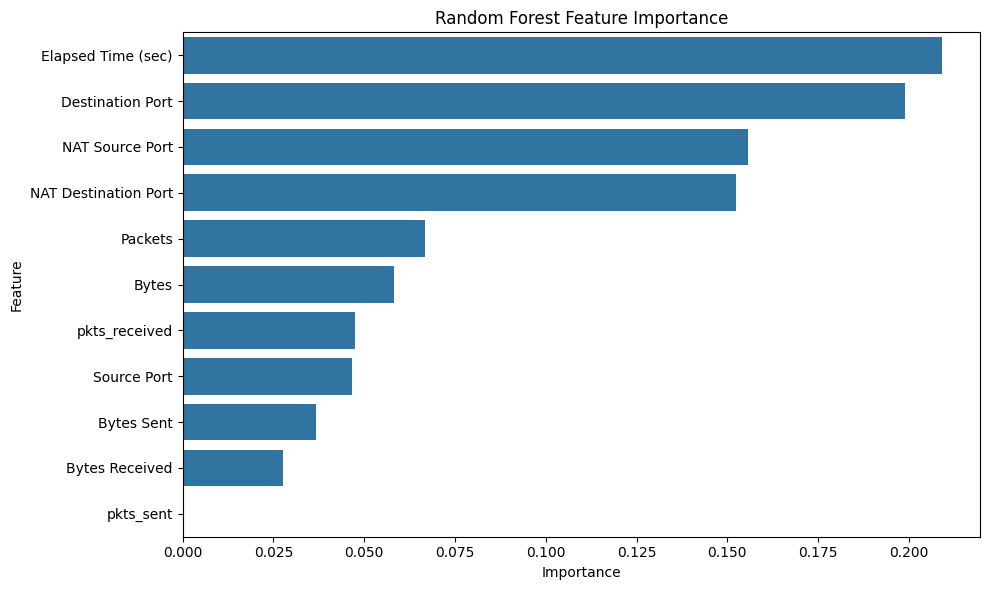

In [10]:
# ================================================================
# 9. FEATURE IMPORTANCE
# ================================================================

if feature_importance is not None:

    feature_importance.to_csv(
        "project_outputs/feature_importance.csv",
        index=False
    )

    plt.figure(figsize=(10,6))
    sns.barplot(
        data=feature_importance.head(12),
        x="Importance",
        y="Feature"
    )
    plt.title("Random Forest Feature Importance")
    plt.tight_layout()
    plt.savefig(
        "project_outputs/feature_importance.png",
        dpi=250
    )
    plt.show()
    plt.close()


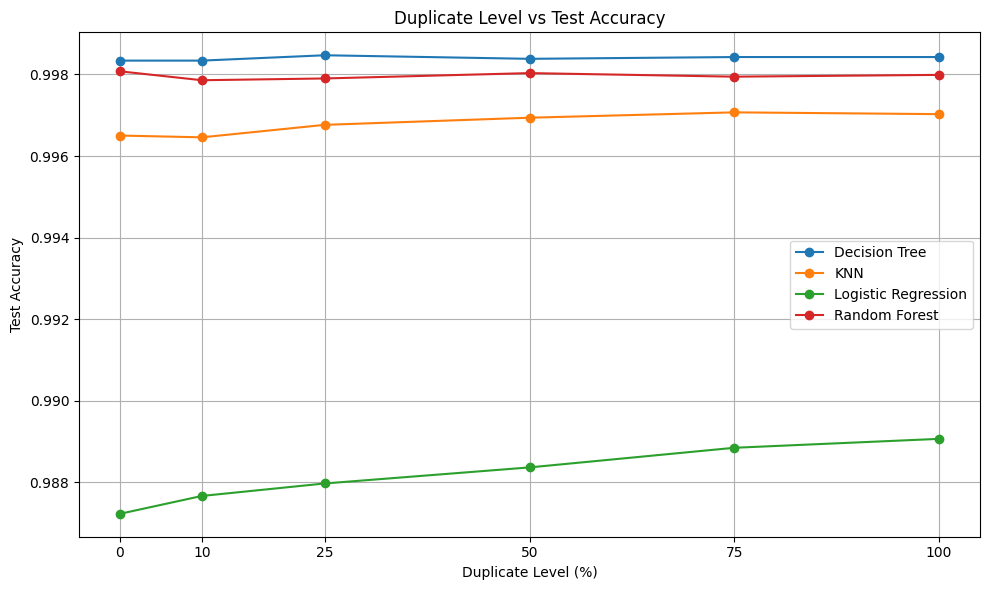

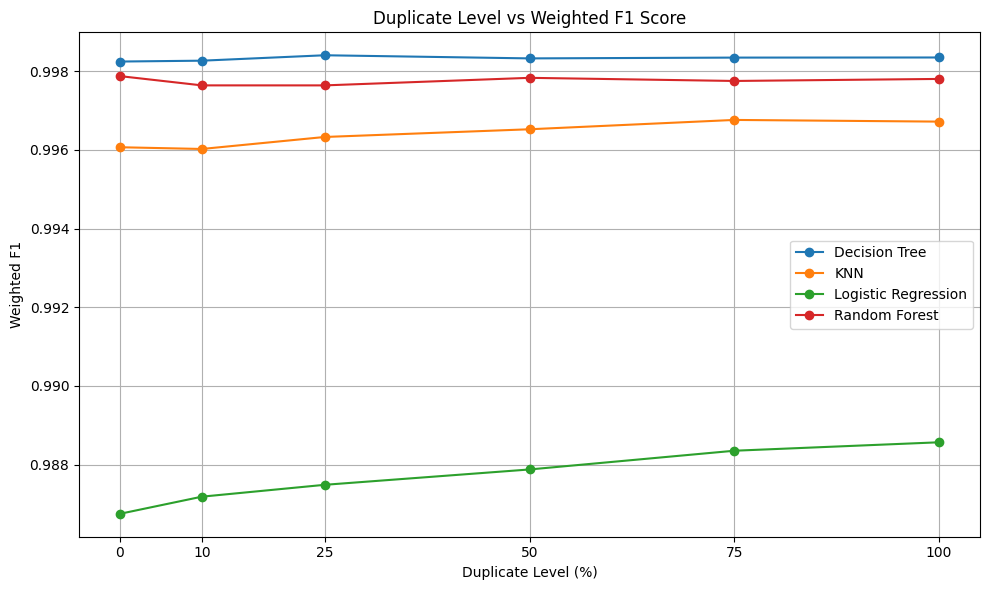

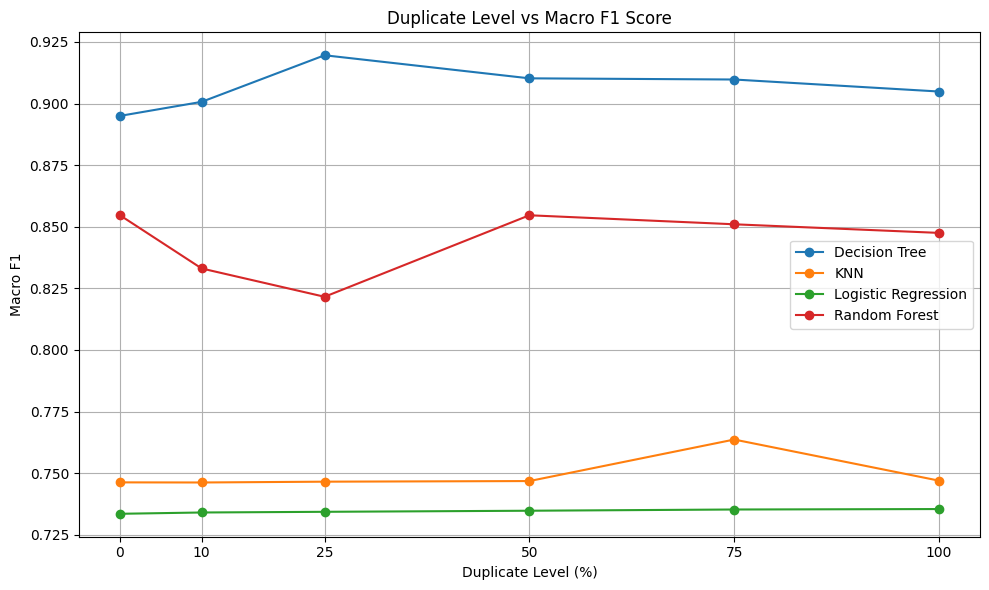

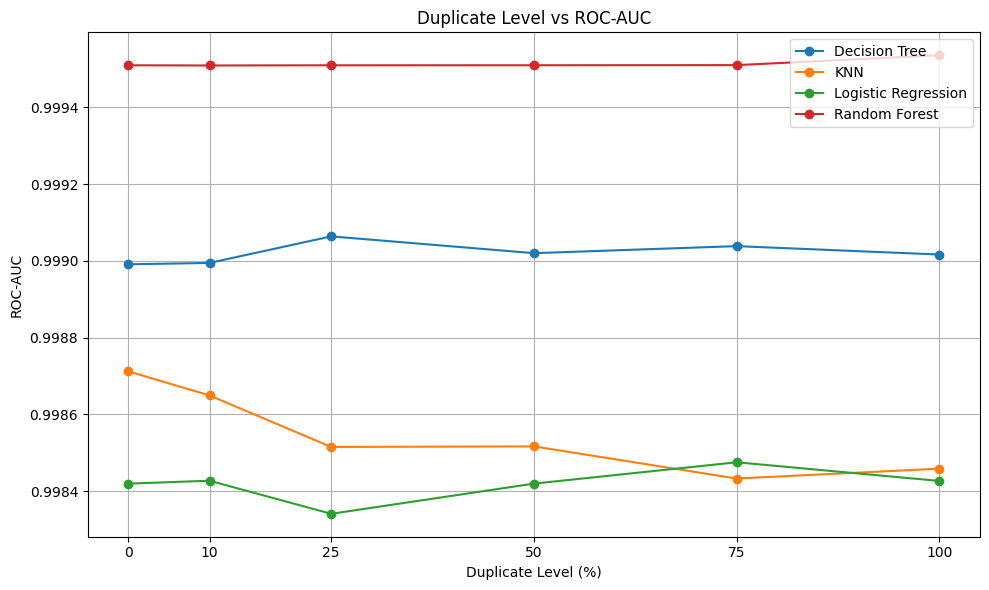

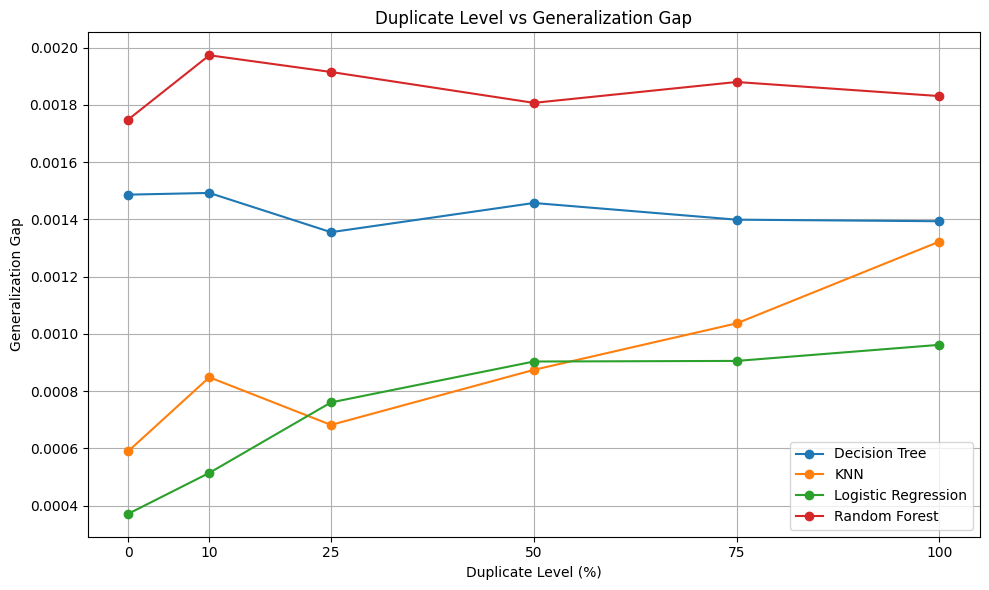

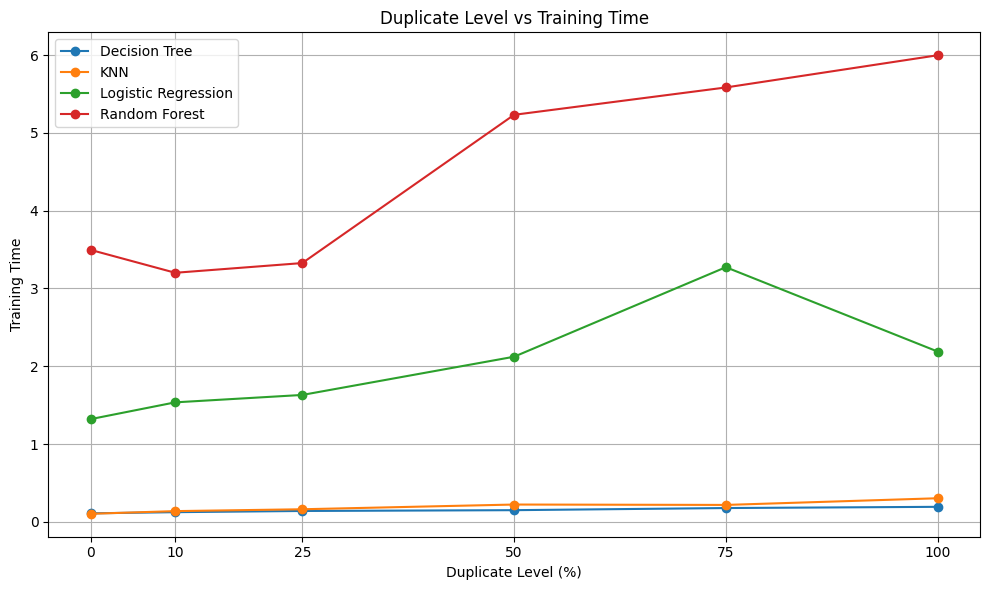

In [11]:
# 10. PERFORMANCE VISUALIZATION FUNCTION
# ================================================================

metrics = [
    ("Test Accuracy", "Duplicate Level vs Test Accuracy"),
    ("Weighted F1", "Duplicate Level vs Weighted F1 Score"),
    ("Macro F1", "Duplicate Level vs Macro F1 Score"),
    ("ROC-AUC", "Duplicate Level vs ROC-AUC"),
    ("Generalization Gap", "Duplicate Level vs Generalization Gap"),
    ("Training Time", "Duplicate Level vs Training Time")
]

for metric, title in metrics:

    plt.figure(figsize=(10,6))

    for model_name in average_results["Model"].unique():

        selected = average_results[
            average_results["Model"] == model_name
        ]

        plt.plot(
            selected["Duplicate Level"],
            selected[metric],
            marker="o",
            label=model_name
        )

    plt.title(title)
    plt.xlabel("Duplicate Level (%)")
    plt.ylabel(metric)
    plt.xticks(duplicate_levels)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    filename = metric.lower().replace(" ", "_") + ".png"

    plt.savefig(
        f"project_outputs/{filename}",
        dpi=250
    )

    plt.show()
    plt.close()


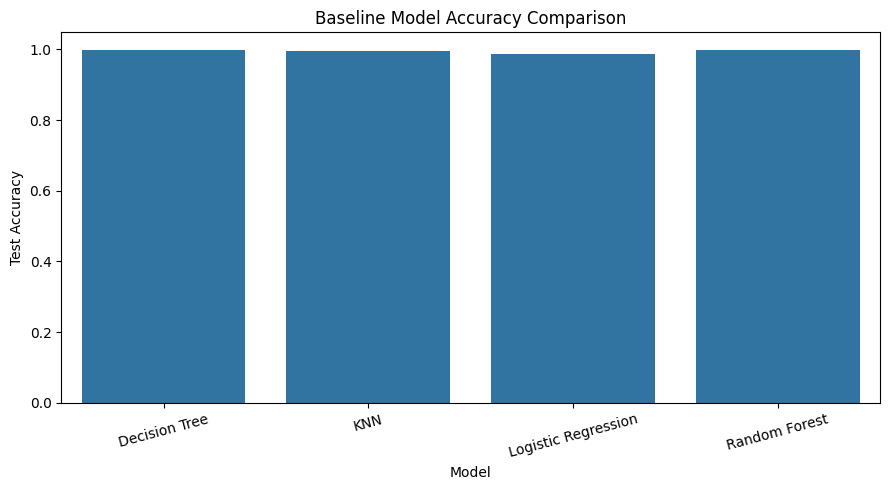

In [12]:
# ================================================================
# 11. MODEL COMPARISON BAR CHART
# ================================================================

baseline = average_results[
    average_results["Duplicate Level"] == 0
]

plt.figure(figsize=(9,5))
sns.barplot(
    data=baseline,
    x="Model",
    y="Test Accuracy"
)
plt.title("Baseline Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    "project_outputs/baseline_model_comparison.png",
    dpi=250
)
plt.show()
plt.close()


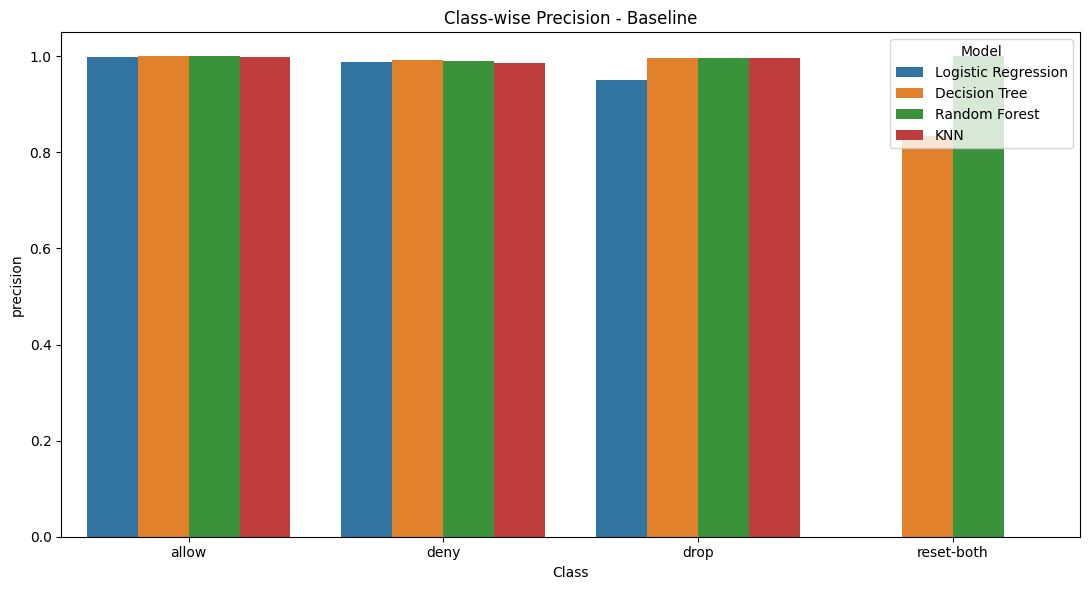

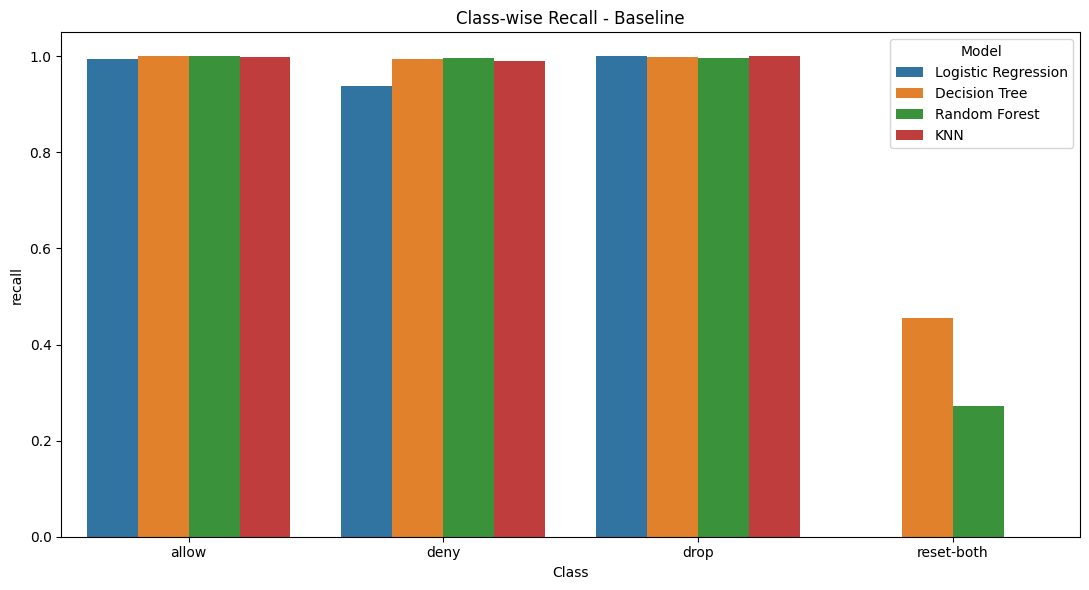

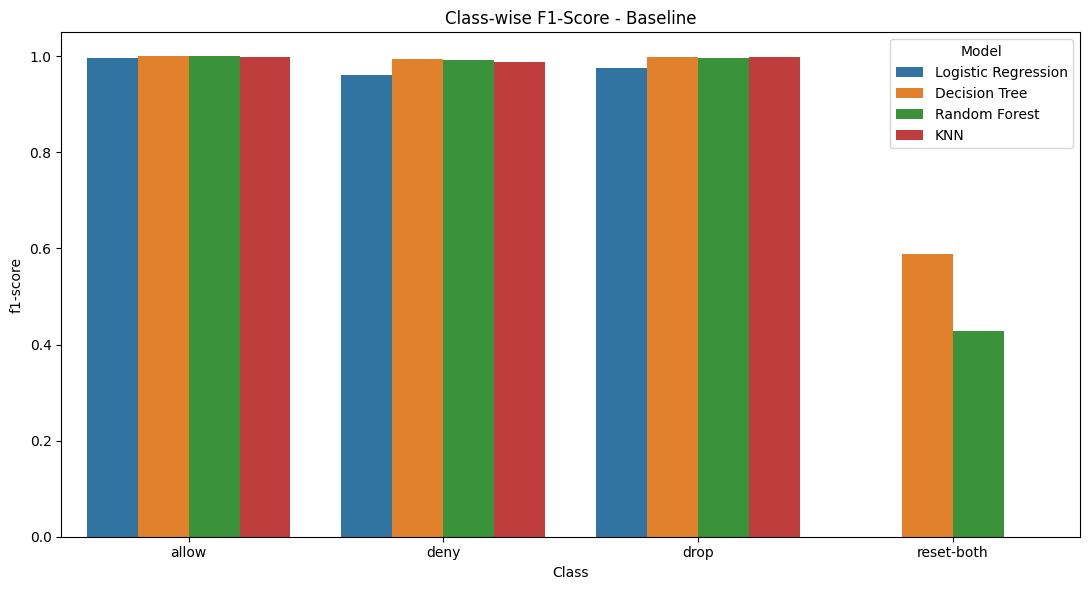

In [13]:
# ================================================================
# 12. CLASS-WISE PERFORMANCE VISUALIZATION
# ================================================================

if not reports_df.empty:

    class_reports = reports_df[
        reports_df["Class"].isin(class_names)
    ]

    for metric in ["precision", "recall", "f1-score"]:

        plt.figure(figsize=(11,6))

        sns.barplot(
            data=class_reports[class_reports["Duplicate Level"] == 0],
            x="Class",
            y=metric,
            hue="Model"
        )

        plt.title(f"Class-wise {metric.title()} - Baseline")
        plt.tight_layout()
        plt.savefig(
            f"project_outputs/classwise_{metric}.png",
            dpi=250
        )
        plt.show()
        plt.close()


In [14]:
# ================================================================
# 13. FINAL MODEL RANKING
# ================================================================

ranking = baseline.sort_values(
    "Test Accuracy",
    ascending=False
)[["Model", "Test Accuracy", "Weighted F1", "ROC-AUC"]]

print("\nBASELINE MODEL RANKING")
display(ranking.round(4))

# ================================================================
# 14. AUTOMATIC RESULT SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("FINAL MINI PROJECT SUMMARY")
print("=" * 65)

print("Dataset records after cleaning:", len(df))
print("Original exact duplicates:", original_duplicates)
print("Number of features:", X.shape[1])
print("Number of classes:", len(class_names))
print("Classes:", list(class_names))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Duplicate levels:", duplicate_levels)
print("Models:", list(create_models().keys()))
print("Random seeds:", seeds)
print("Total model experiments:", len(results_df))

print("\nBest baseline model:")
print(ranking.iloc[0].to_string())

print("\nAll files saved inside project_outputs folder.")



BASELINE MODEL RANKING


,Model,Test Accuracy,Weighted F1,ROC-AUC
0,Decision Tree,0.9983,0.9982,0.9990
3,Random Forest,0.9981,0.9979,0.9995
1,KNN,0.9965,0.9961,0.9987
2,Logistic Regression,0.9872,0.9867,0.9984



FINAL MINI PROJECT SUMMARY
Dataset records after cleaning: 57170
Original exact duplicates: 8362
Number of features: 11
Number of classes: 4
Classes: ['allow', 'deny', 'drop', 'reset-both']
Training records: 45736
Testing records: 11434
Duplicate levels: [0, 10, 25, 50, 75, 100]
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN']
Random seeds: [42, 123]
Total model experiments: 48

Best baseline model:
Model            Decision Tree
Test Accuracy         0.998338
Weighted F1           0.998249
ROC-AUC               0.998991

All files saved inside project_outputs folder.


In [15]:
# ================================================================
# 15. ZIP ALL PROJECT OUTPUTS
# ================================================================

with zipfile.ZipFile(
    "mini_project_outputs.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk("project_outputs"):
        for file in files:
            path = os.path.join(root, file)
            zip_file.write(path)

print("\nZIP FILE CREATED: mini_project_outputs.zip")

from google.colab import files
files.download("mini_project_outputs.zip")



ZIP FILE CREATED: mini_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>